   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


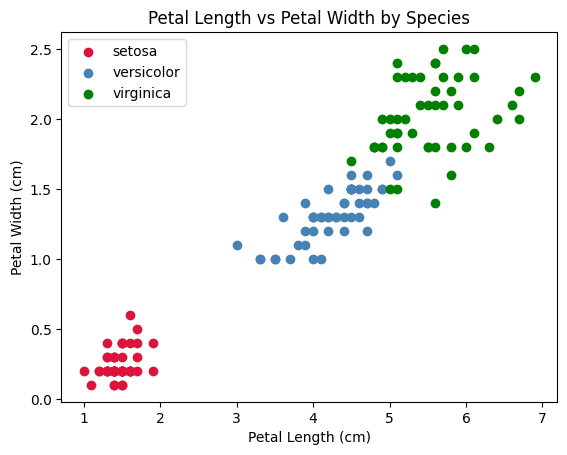

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
Confusion Matrix:
 [[20  0]
 [ 0 10]]


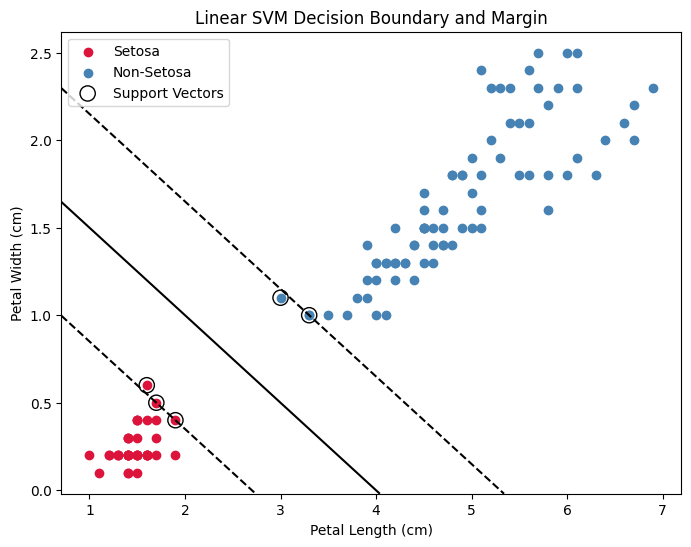

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Load Iris dataset
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target_names[iris.target]

print(df.head())
print(df['species'].value_counts())

# Visualize petal features
for species, color in zip(iris.target_names, ['crimson', 'steelblue', 'green']):
    subset = df[df['species'] == species]
    plt.scatter(subset['petal length (cm)'],
                subset['petal width (cm)'],
                label=species, color=color)

plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('Petal Length vs Petal Width by Species')
plt.legend()
plt.show()

# Select features and create binary labels
X = df[['petal length (cm)', 'petal width (cm)']].values
y = (iris.target == 0).astype(int)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Linear SVM
svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X_train_scaled, y_train)

# Predict and evaluate
y_pred = svm_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Visualize decision boundary, margins and support vectors
def plot_svm_boundary(model, X, y, scaler):
    X_orig = scaler.inverse_transform(X)

    plt.figure(figsize=(8, 6))
    plt.scatter(X_orig[y == 1, 0], X_orig[y == 1, 1],
                color='crimson', label='Setosa')
    plt.scatter(X_orig[y == 0, 0], X_orig[y == 0, 1],
                color='steelblue', label='Non-Setosa')

    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    xx = np.linspace(xlim[0], xlim[1], 200)
    yy = np.linspace(ylim[0], ylim[1], 200)
    YY, XX = np.meshgrid(yy, xx)

    points = np.c_[XX.ravel(), YY.ravel()]
    points_scaled = scaler.transform(points)
    Z = model.decision_function(points_scaled).reshape(XX.shape)

    ax.contour(XX, YY, Z, levels=[-1, 0, 1],
               colors='black', linestyles=['--', '-', '--'])

    support_vectors = scaler.inverse_transform(model.support_vectors_)
    ax.scatter(support_vectors[:, 0], support_vectors[:, 1],
               s=120, facecolors='none', edgecolors='black',
               label='Support Vectors')

    plt.xlabel('Petal Length (cm)')
    plt.ylabel('Petal Width (cm)')
    plt.title('Linear SVM Decision Boundary and Margin')
    plt.legend()
    plt.show()

plot_svm_boundary(svm_model, X_train_scaled, y_train, scaler)
